In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
import scipy
from scipy.stats import multivariate_normal

print("Installations Working!")

Installations Working!


## Distribution Setup


In [26]:
# Parameter Definitions

# Priors
p1, p2, p3, p4 = .25, .25, .25, .25


# Set Random Seed
rng = np.random.default_rng(1)

mu1 = [3, 1.5, 3]
mu2 = [1, -3, -1.5]
mu3 = [-4, 3, -3]
mu4 = [-2, -.5, 3]


# Quick verification of mean equidistance


cov1 = [[4,   -1.5, .5],
              [-1.5, 4, 1],
              [.5, 1, 10]]

cov2 = [[2,   -.2, -.5],
              [-.2, 4, .5],
              [-.5, .5, 3]]

cov3 = [[2, .1, .5],
              [.1, 3, 1],
              [.5, 1, 3]]

cov4 = [[4, .1, .5],
              [.1, 4, .1],
              [.5, .1, 1]]



# Class overlap with Bhattacharyya Bound

def Bhattacharyya(mu1, mu2, cov1, cov2):
    mu1 = np.asarray(mu1).reshape(-1, 1)
    mu2 = np.asarray(mu2).reshape(-1, 1)
    
    diff = mu2 - mu1
    s_cov = (np.asarray(cov2) + np.asarray(cov1)) / 2

    B = .125 * diff.T @ np.linalg.inv(s_cov) @ diff + .5 * np.log(np.linalg.det(s_cov) / np.sqrt(np.linalg.det(cov1) * np.linalg.det(cov2)))

    return B

parameters = [[mu1, cov1], [mu2, cov2], [mu3, cov3], [mu4, cov4]]

iter = 1
B_pairs = []
err = 0
count = 0
for mu1, cov1 in parameters:

    parameters_2 = parameters.copy()[iter :]
    
    for mu2, cov2 in parameters_2:
        B = Bhattacharyya(mu1, mu2, cov1, cov2)
        err += .25 * np.exp(-B)
        count +=1
    iter += 1        
    

print(f"Expected Error from BB: {err}")
print(count)

Expected Error from BB: [[0.19919823]]
6


In [31]:


def make_dist(N):
    rng = np.random.default_rng(42)

    priors = [.25, .25, .25, .25]
    labels = rng.choice(4, size=N, p=priors)
    X = np.zeros((N, 3))   # d = dimension of your data

    dist_stack = []
    
    for c in range(4):
        mu, C = parameters[c]
        idx = (labels == c)
        X[idx] = g(mu, C, N)
        
        dist_stack.append(rng.multivariate_normal(mu, C, size=idx.sum()))


    X_dist = np.vstack(dist_stack)

    n = int(N / 4)

    L = np.concatenate([np.full(n, 1), np.full(n, 2), np.full(n, 3), np.full(n,4)])
    # Verification


    return L, X_dist

In [35]:
L_100, X_100 = make_dist(100)
L_500, X_500 = make_dist(500)
L_1000, X_1000 = make_dist(1000)
L_5000, X_5000 = make_dist(5000)
L_10000, X_10000 = make_dist(10000)
L_100000, X_100000 = make_dist(100000)

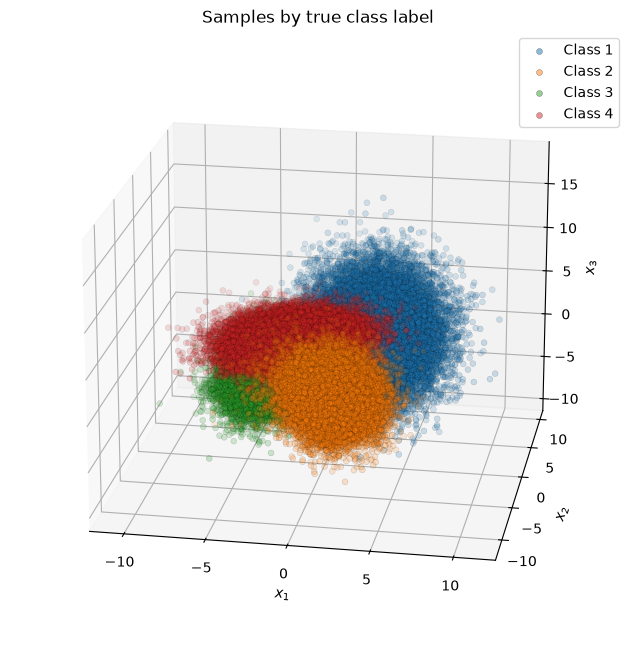

In [41]:
fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(projection='3d')
markers = {1: 'o', 2: 'o', 3: 'o', 4: 'o'}                         # circle, triangle, square
colors  = {1: 'tab:blue', 2: 'tab:orange', 3: 'tab:green', 4: 'tab:red'}

for k in [1, 2, 3, 4]:
    pts = X_100000[L_100000 == k]
    ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2],
               marker=markers[k], color=colors[k],
               s=18, alpha=0.5, edgecolors='k', linewidths=0.3,
               label=f"Class {k}")
ax.view_init(elev=20, azim=280)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("$x_3$")
ax.set_title("Samples by true class label")
ax.legend()
plt.show()